# Training and explaining the model on C-MAPSS FD001

**Notebook 02 of the thesis project "Explainable Graph Neural Networks for Remaining Useful Life prediction".**

---

## What this notebook is for

Notebook 01 turned the raw NASA files into arrays. This one takes those arrays and does the remaining four things:

1. **builds** the network that Wen et al. (2026) describe in their Table 4,
2. **trains** it with the settings in their Table 6,
3. **scores** it with the four measures in their Section 3.3, and
4. **explains** it with the Shapley values of their Section 2.4.

As in notebook 01, every step has three parts: what it does, why it is done that way, and a check confirming it did what was intended.

## What you need before running it

The real NASA FD001 files in `data/raw/`, and PyTorch. Section 5 of `README.md` covers the download and section 4 covers PyTorch. Running the whole notebook takes about five minutes on a CPU, most of it two training runs.

## The one thing to keep in mind throughout

The per-sensor LSTM stage of the paper is **not** implemented here. Its size, its depth, and how it turns a 30-cycle window into the single number Table 4 requires are never stated in the paper, so building it would be invention rather than reproduction.

The paper publishes results for exactly this configuration itself, as the **"ESTGNN w/o LSTM"** row of its ablation table. Every comparison below is against that row, and never against the headline figures. See assumptions A-07 and A-11 in `docs/ASSUMPTIONS.md`.

## 1. Setup

Each import line is a path through the project's folders: `thesis_gnn_rul_xai.models.estgnn` is the file `src/thesis_gnn_rul_xai/models/estgnn.py`. Section 9 of `README.md` explains the layout.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from thesis_gnn_rul_xai.config import load_config
from thesis_gnn_rul_xai.data.pipeline import run_preprocessing
from thesis_gnn_rul_xai.evaluation import evaluate, prediction_error
from thesis_gnn_rul_xai.explain import (
    dynamic_shap,
    efficiency_error,
    mean_window_baseline,
    shap_summary,
    shap_values,
)
from thesis_gnn_rul_xai.graph.adjacency import (
    build_fully_connected_adjacency,
    normalize_adjacency,
)
from thesis_gnn_rul_xai.models import ESTGNN
from thesis_gnn_rul_xai.training import TrainingConfig, evaluate_model, predict, train
from thesis_gnn_rul_xai.utils.logging_setup import configure_logging

configure_logging()
plt.rcParams["figure.dpi"] = 110
print(f"PyTorch {torch.__version__}   CUDA available: {torch.cuda.is_available()}")

PyTorch 2.13.0+cpu   CUDA available: False


## 2. The data

Everything notebook 01 produced, in one call. Nothing new happens here; if any of it is unfamiliar, read notebook 01 first.

In [2]:
config = load_config(PROJECT_ROOT / "config" / "fd001.yaml")
prepared = run_preprocessing(config, data_dir=PROJECT_ROOT / "data" / "raw")
print()
display(prepared.summary())

16:04:58 | INFO    | thesis_gnn_rul_xai.data.loading | Loading FD001 from D:\Main\University\Thesis\Code\Thesis GNN RUL XAI\data\raw


16:04:59 | INFO    | thesis_gnn_rul_xai.data.loading | FD001 matches the published shape of the official release.


16:04:59 | INFO    | thesis_gnn_rul_xai.data.loading | Loaded FD001: 20631 training rows over 100 engines, 13096 test rows over 100 engines.


16:04:59 | WARNING | thesis_gnn_rul_xai.data.pipeline | The paper keeps sensor(s) ['P15'], but in this data they carry no usable variation. They are kept anyway, because the adjacency matrix is defined over the paper's fixed 14-sensor set. Report this observation rather than silently changing the selection.


16:04:59 | INFO    | thesis_gnn_rul_xai.data.smoothing | Applied exponentially weighted moving average (alpha=0.500) to 14 columns across 100 engines.


16:04:59 | INFO    | thesis_gnn_rul_xai.data.smoothing | Applied exponentially weighted moving average (alpha=0.500) to 14 columns across 100 engines.


... (4 outputs left out)

16:04:59 | INFO    | thesis_gnn_rul_xai.data.windowing | Built 17731 window(s) of shape (14, 30) from 100 engine(s).


16:04:59 | INFO    | thesis_gnn_rul_xai.data.windowing | Built 100 window(s) of shape (14, 30) from 100 engine(s).


16:04:59 | INFO    | thesis_gnn_rul_xai.data.pipeline | Preprocessing complete: 14459 training, 3272 validation, 100 test example(s).


,examples,engines,feature_shape,target_min,target_max
split,,,,,
train,14459,80,"(14, 30)",0.0,125.0
validation,3272,20,"(14, 30)",0.0,125.0
test,100,100,"(14, 30)",7.0,125.0


**Check.** Three things must hold before anything below is meaningful, and all three were established in notebook 01:

- the feature axis has 14 entries, one per graph node, in the paper's Table 3 order;
- no engine appears in both the training and the validation split;
- each test engine contributes exactly one window, which is the single moment the official labels describe.

In [3]:
assert prepared.train.features.shape[1] == 14
assert set(prepared.train.units.tolist()).isdisjoint(prepared.validation.units.tolist())
assert len(prepared.test) == len(np.unique(prepared.test.units))
print(f"OK  {len(prepared.train):>6} training windows from {len(np.unique(prepared.train.units)):>3} engines")
print(f"OK  {len(prepared.validation):>6} validation windows from {len(np.unique(prepared.validation.units)):>3} engines")
print(f"OK  {len(prepared.test):>6} test windows from {len(np.unique(prepared.test.units)):>3} engines")
print(f"\nOne example has shape {prepared.train.features.shape[1:]}: 14 sensors, 30 cycles each.")

OK   14459 training windows from  80 engines
OK    3272 validation windows from  20 engines
OK     100 test windows from 100 engines

One example has shape (14, 30): 14 sensors, 30 cycles each.


## 3. Step 9 — Build the network

### What a graph convolution does

Each of the three graph layers updates every sensor by mixing its own values with those of the sensors it is connected to, then applying a learned linear transformation:

$$H' = \mathrm{ReLU}\left(\hat{A} \, H \, W\right)$$

- $H$ holds the current features, one row per sensor.
- $\hat{A}$ is the sensor graph, fixed, with self-loops added and each edge divided by the degrees it joins. It is **not learned** — it is the engineering knowledge the paper builds in.
- $W$ is learned.

One layer lets a sensor see its direct neighbours. Three layers let it see three edges away.

### The architecture

Table 4 of the paper specifies every dimension, so nothing here is a guess. The cell below prints the network in the same form as that table, for checking side by side.

In [4]:
model = ESTGNN(
    prepared.adjacency_normalized,
    in_features=prepared.train.features.shape[2],
    rul_max=config.rul_max,
)
print()
display(pd.DataFrame(model.layer_summary()))
print(f"Trainable parameters: {model.count_parameters():,}")

16:04:59 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 30 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 62657 trainable parameters.


,layer,type,in,out,parameters,activation
0,Input,Node features,"(B, 14, 30)","(B, 14, 30)",0,-
1,GCN-1,GCN,"(B, 14, 30)","(B, 14, 32)",960,ReLU
2,GCN-2,GCN,"(B, 14, 32)","(B, 14, 64)",2048,ReLU
3,GCN-3,GCN,"(B, 14, 64)","(B, 14, 32)",2048,ReLU
4,Flatten,Tensor reshape,"(B, 14, 32)","(B, 448)",0,-
5,FC-1,Fully connected,"(B, 448)","(B, 128)",57472,ReLU
6,FC-2,Fully connected,"(B, 128)","(B, 1)",129,Sigmoid


Trainable parameters: 62,657


**Check.** With `in_features=1` — the shape Table 4 actually prints, which is what the omitted LSTM would have produced — the parameter count must match the weight matrices the paper lists: $W^{(1)}\in\mathbb{R}^{1\times32}$, $W^{(2)}\in\mathbb{R}^{32\times64}$, $W^{(3)}\in\mathbb{R}^{64\times32}$, $W_{fc1}\in\mathbb{R}^{448\times128}$, $W_{fc2}\in\mathbb{R}^{128\times1}$.

In [5]:
table4 = ESTGNN(prepared.adjacency_normalized, in_features=1, rul_max=config.rul_max)
expected = 1*32 + 32*64 + 64*32 + (448*128 + 128) + (128*1 + 1)
assert table4.count_parameters() == expected == 61_729
print(f"OK  Table 4 configuration has exactly {expected:,} parameters.")
print(f"    Ours has {model.count_parameters():,}: the extra {model.count_parameters()-expected:,}")
print(f"    are the first weight matrix widening from 1 to 30 inputs, because each")
print(f"    node carries its whole window instead of one LSTM output (A-07).")

16:04:59 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 1 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 61729 trainable parameters.


OK  Table 4 configuration has exactly 61,729 parameters.
    Ours has 62,657: the extra 928
    are the first weight matrix widening from 1 to 30 inputs, because each
    node carries its whole window instead of one LSTM output (A-07).


### What the graph lets the model see, and what it does not

The graph is fixed, so its shape bounds what any amount of training can express. Two facts about it are worth knowing before looking at any result.

**Some sensors are four edges apart.** With three layers, information travels at most three edges, so those pairs can never influence each other. The check below perturbs `P15` and confirms `W32` does not move at all, while `P15`'s direct neighbour `Nf` does.

**`T24` is the only articulation point.** Removing it would split the sensors into a fan group and a core group, so every message between those groups passes through it. That is a fact about the published graph, and a ready-made target for the graph-native explanation methods that come after SHAP.

In [6]:
order = list(prepared.sensor_symbols)

def three_graph_layers(features: torch.Tensor) -> torch.Tensor:
    hidden = features
    for layer in model.graph_layers:
        hidden = torch.relu(layer(hidden, model.adjacency))
    return hidden

base = torch.randn(1, 14, prepared.train.features.shape[2])
bumped = base.clone()
bumped[0, order.index("P15")] += 100.0

with torch.no_grad():
    before, after = three_graph_layers(base), three_graph_layers(bumped)

far = float((before[0, order.index("W32")] - after[0, order.index("W32")]).abs().max())
near = float((before[0, order.index("Nf")] - after[0, order.index("Nf")]).abs().max())
print(f"Perturbing P15 by +100, after three graph layers:")
print(f"  W32 (four edges away) changed by {far:.2e}   <- unreachable, exactly zero")
print(f"  Nf  (one edge away)   changed by {near:.2f}")
assert far == 0.0 and near > 0
print("\nOK  Message passing follows the sensor graph and nothing else.")

Perturbing P15 by +100, after three graph layers:
  W32 (four edges away) changed by 0.00e+00   <- unreachable, exactly zero
  Nf  (one edge away)   changed by 26.19

OK  Message passing follows the sensor graph and nothing else.


## 4. Step 10 — Train

Table 6 of the paper gives Adam, 200 epochs, batch size 32, a learning rate falling from $10^{-3}$ to $10^{-4}$, and mean squared error. Two things it does not give are recorded as assumptions rather than hidden in the code: **how** the learning rate travels between those two values (A-17), and when to stop early (A-18).

### Why the targets are divided by 125

The network ends in a sigmoid, so its output is between 0 and 1. A label measured in cycles could never be reached by such a layer. Targets are therefore divided by `rul_max` for training and predictions multiplied back, which is assumption A-13 and is forced rather than chosen.

It has one consequence worth stating: **the model cannot predict a remaining life above 125 for any input whatsoever.** That is the architectural fact assumption A-02 rests on.

In [7]:
training = TrainingConfig(seed=42, device="cpu")
print("Settings taken from Table 6:")
for key in ("epochs", "batch_size", "learning_rate", "final_learning_rate", "optimizer", "loss"):
    print(f"  {key:22s} {getattr(training, key)}")
print("\nSettings the paper does not give (see docs/ASSUMPTIONS.md):")
for key, note in (("lr_schedule", "A-17"), ("early_stopping_patience", "A-18")):
    print(f"  {key:22s} {getattr(training, key)}   ({note})")

Settings taken from Table 6:
  epochs                 200
  batch_size             32
  learning_rate          0.001
  final_learning_rate    0.0001
  optimizer              adam
  loss                   mse

Settings the paper does not give (see docs/ASSUMPTIONS.md):
  lr_schedule            exponential   (A-17)
  early_stopping_patience 20   (A-18)


In [8]:
torch.manual_seed(training.seed)
model = ESTGNN(
    prepared.adjacency_normalized,
    in_features=prepared.train.features.shape[2],
    rul_max=config.rul_max,
)
history = train(model, prepared.train, prepared.validation, training)
print()
print(history.summary())

16:04:59 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 30 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 62657 trainable parameters.


16:05:01 | INFO    | thesis_gnn_rul_xai.training.loop | Training for up to 200 epoch(s) on 14459 window(s), batch size 32, learning rate 1.0e-03 -> 1.0e-04 (exponential schedule).


16:05:03 | INFO    | thesis_gnn_rul_xai.training.loop | epoch    1/200  train 0.06242  validation 28.603 cycles  lr 1.00e-03


16:05:14 | INFO    | thesis_gnn_rul_xai.training.loop | epoch   10/200  train 0.02986  validation 21.433 cycles  lr 9.01e-04


16:05:27 | INFO    | thesis_gnn_rul_xai.training.loop | epoch   20/200  train 0.02747  validation 21.229 cycles  lr 8.03e-04


16:05:39 | INFO    | thesis_gnn_rul_xai.training.loop | epoch   30/200  train 0.02464  validation 23.264 cycles  lr 7.15e-04


... (6 outputs left out)

16:07:01 | INFO    | thesis_gnn_rul_xai.training.loop | epoch  100/200  train 0.01718  validation 16.977 cycles  lr 3.18e-04


16:07:09 | INFO    | thesis_gnn_rul_xai.training.loop | Stopping at epoch 107: the validation error has not improved for 20 epoch(s). Restoring the weights from epoch 87.


16:07:09 | INFO    | thesis_gnn_rul_xai.training.loop | Trained for 107 epoch(s) in 127.6s, ending on early stopping. Best validation error 16.745 cycles at epoch 87. The model holds the weights from that epoch.



Trained for 107 epoch(s) in 127.6s, ending on early stopping. Best validation error 16.745 cycles at epoch 87. The model holds the weights from that epoch.


### The learning curve

The training loss is on the normalised scale the network sees; the validation error is in flight cycles, which is the only unit anyone can reason about. The vertical line marks the epoch whose weights the model now holds — not the last epoch, but the best one.

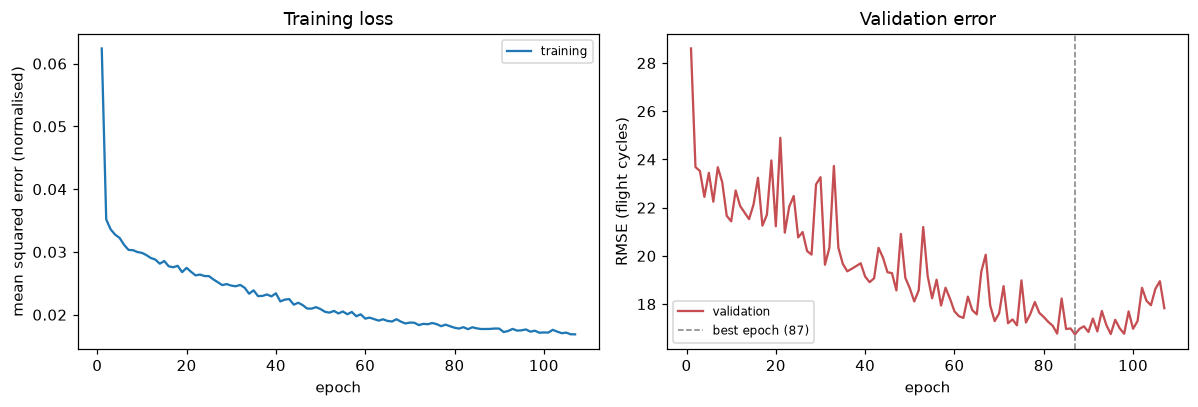

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].plot(history.epochs["epoch"], history.epochs["train_loss"], label="training")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("mean squared error (normalised)")
axes[0].set_title("Training loss"); axes[0].legend(fontsize=8)

axes[1].plot(history.epochs["epoch"], history.epochs["validation_rmse_cycles"],
             color="#C44E52", label="validation")
axes[1].axvline(history.best_epoch, color="grey", linestyle="--", linewidth=1,
                label=f"best epoch ({history.best_epoch})")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("RMSE (flight cycles)")
axes[1].set_title("Validation error"); axes[1].legend(fontsize=8)

fig.tight_layout(); plt.show()

**A warning about the right-hand panel.** That number is *not* comparable with the test error below, and the gap between them means nothing about the model. The two sets weight their engines completely differently: validation holds every window of 20 engines, so a single unusual engine contributing 240 windows can move the figure, while each of the 100 test engines contributes exactly one window and is worth exactly one per cent. Validation error is the right signal for deciding when to stop; it is the wrong number to publish. See assumption A-06.

## 5. Step 11 — Score

Four measures, all defined in Section 3.3 of the paper, all computed over the 100 test engines from one prediction each. With `d = ŷ - y` the error in cycles:

| Measure | Formula | Direction |
|---|---|---|
| RMSE | $\sqrt{\frac{1}{N}\sum d^2}$ | lower is better |
| NASA score | $\sum s$, with $s = e^{-d/13}-1$ if $d<0$, else $e^{d/10}-1$ | lower is better |
| R² | $1 - \sum(\hat{y}-y)^2 / \sum(y-\bar{y})^2$ | higher is better, 1 is perfect |
| ASUE | $\frac{1}{N_{under}}\sum \max(0,\, y-\hat{y})$ | lower is better |

The score is asymmetric on purpose: the divisor 10 for a late prediction is smaller than the 13 for an early one, so the same error costs more when the model claimed more life than the engine had. **The paper's Equations 20 and 21 contradict each other about which direction that is**; the convention used here is the one its own prose describes and the one the 2008 challenge defines. See assumption A-15.

In [10]:
result = evaluate_model(model, prepared.test)
print("FD001 test set, one prediction per engine, single seed:\n")
for key, label in (("rmse", "RMSE"), ("score", "NASA score"), ("r2", "R-squared"), ("asue", "ASUE")):
    print(f"  {label:12s} {result[key]:9.3f}")
print(f"\n  engines       {result['n_engines']:9d}")
print(f"  optimistic on {result['n_late']:9d}  (the dangerous direction)")
print(f"  mean error    {result['mean_error']:+9.3f}  cycles")

FD001 test set, one prediction per engine, single seed:

  RMSE            13.408
  NASA score     301.884
  R-squared        0.888
  ASUE             8.944

  engines             100
  optimistic on        40  (the dangerous direction)
  mean error       -0.950  cycles


### How that compares with the paper

Table 11 of the paper reports **RMSE only** for its ablations, so `w/o LSTM` has no published score, R² or ASUE. The single comparable number is its FD001 RMSE of **14.93**.

In [11]:
comparison = pd.DataFrame([
    {"source": "this notebook (1 seed)", "RMSE": round(result["rmse"], 2),
     "NASA score": round(result["score"], 1), "R2": round(result["r2"], 3),
     "ASUE": round(result["asue"], 2)},
    {"source": "paper, ESTGNN w/o LSTM", "RMSE": 14.93,
     "NASA score": None, "R2": None, "ASUE": None},
    {"source": "paper, ESTGNN full", "RMSE": 11.78,
     "NASA score": 278.6, "R2": 0.921, "ASUE": 8.312},
])
display(comparison)
print("The comparable row is 'w/o LSTM', because the LSTM stage is not")
print("implemented here (A-11). The full model's numbers are shown only for")
print("scale, and no claim about them can be made from this code.")

,source,RMSE,NASA score,R2,ASUE
0,this notebook (1 seed),13.41,301.9,0.888,8.940
1,"paper, ESTGNN w/o LSTM",14.93,NaN,NaN,NaN
2,"paper, ESTGNN full",11.78,278.6,0.921,8.312


The comparable row is 'w/o LSTM', because the LSTM stage is not
implemented here (A-11). The full model's numbers are shown only for
scale, and no claim about them can be made from this code.


**One seed is not evidence.** The figure above comes from a single run and will move by a few tenths with the seed. The reported result for this project is the mean over five seeds, which `scripts/train.py --seeds 5` produces:

```
RMSE 13.45 +/- 0.20    score 312 +/- 11    R2 0.887 +/- 0.003    ASUE 8.85 +/- 0.36
```

Section 8 of `README.md` records what that comparison does and does not establish. In short: this code lands **better** than the published figure, which is not a reproduction, and the differences are all documented as assumptions — the input rescaling is substituted from another paper (A-03), early stopping is an addition (A-18), and capping the test labels can only help (A-02).

### Predicted against true, engine by engine

This is the analogue of Fig. 8 in the paper. The left panel plots one point per test engine; the right shows how the errors are distributed, split into the safe direction and the dangerous one.

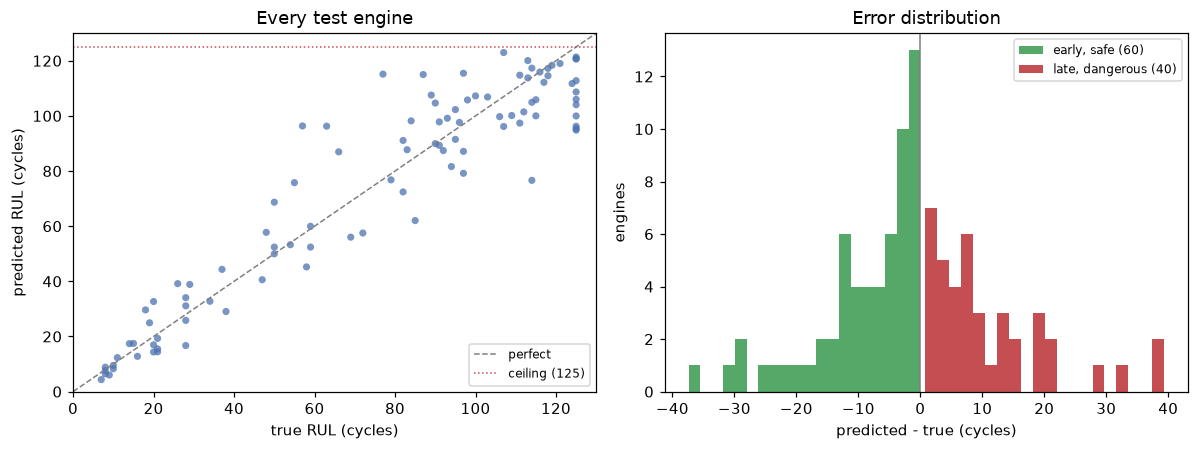

Nothing can sit above the dotted line at 125: the sigmoid output makes it
impossible. That is why assumption A-02 caps the test labels as well.


In [12]:
truth = prepared.test.targets.astype(float)
guess = predict(model, prepared.test)
error = prediction_error(truth, guess)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].scatter(truth, guess, s=22, alpha=0.75, color="#4C72B0", edgecolor="none")
lims = [0, config.rul_max + 5]
axes[0].plot(lims, lims, color="grey", linestyle="--", linewidth=1, label="perfect")
axes[0].axhline(config.rul_max, color="#C44E52", linestyle=":", linewidth=1,
                label=f"ceiling ({config.rul_max})")
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel("true RUL (cycles)"); axes[0].set_ylabel("predicted RUL (cycles)")
axes[0].set_title("Every test engine"); axes[0].legend(fontsize=8)

axes[1].hist(error[error < 0], bins=20, color="#55A868", label=f"early, safe ({int((error<0).sum())})")
axes[1].hist(error[error >= 0], bins=20, color="#C44E52", label=f"late, dangerous ({int((error>=0).sum())})")
axes[1].axvline(0, color="grey", linewidth=1)
axes[1].set_xlabel("predicted - true (cycles)"); axes[1].set_ylabel("engines")
axes[1].set_title("Error distribution"); axes[1].legend(fontsize=8)

fig.tight_layout(); plt.show()
print("Nothing can sit above the dotted line at 125: the sigmoid output makes it")
print("impossible. That is why assumption A-02 caps the test labels as well.")

In [13]:
assert guess.max() <= config.rul_max + 1e-6
print(f"OK  The largest prediction is {guess.max():.2f}, and the ceiling is {config.rul_max}.")

OK  The largest prediction is 122.98, and the ceiling is 125.


## 6. Does the physics graph actually earn its place?

The paper builds its adjacency matrix by hand from engineering knowledge. The way to find out whether that helps is to replace it with a graph carrying no knowledge at all — every sensor connected to every other — and change nothing else. That is the paper's "without physics prior" ablation, though it never says what replaces the matrix; a complete graph is the reading used here, recorded as assumption A-19.

In [14]:
complete, _ = build_fully_connected_adjacency(14)
torch.manual_seed(training.seed)
ablation = ESTGNN(
    normalize_adjacency(complete),
    in_features=prepared.train.features.shape[2],
    rul_max=config.rul_max,
)
ablation_history = train(ablation, prepared.train, prepared.validation, training)
ablation_result = evaluate_model(ablation, prepared.test)
print()
display(pd.DataFrame([
    {"sensor graph": "physics (paper's Table 3)", **{k: round(result[k], 3) for k in ("rmse","score","r2","asue")}},
    {"sensor graph": "fully connected (A-19)",   **{k: round(ablation_result[k], 3) for k in ("rmse","score","r2","asue")}},
]))
print(f"Removing the physics prior costs {ablation_result['rmse'] - result['rmse']:+.2f} cycles of RMSE here.")

16:07:10 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 30 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 62657 trainable parameters.


16:07:10 | INFO    | thesis_gnn_rul_xai.training.loop | Training for up to 200 epoch(s) on 14459 window(s), batch size 32, learning rate 1.0e-03 -> 1.0e-04 (exponential schedule).


16:07:11 | INFO    | thesis_gnn_rul_xai.training.loop | epoch    1/200  train 0.10111  validation 45.476 cycles  lr 1.00e-03


16:07:22 | INFO    | thesis_gnn_rul_xai.training.loop | epoch   10/200  train 0.03391  validation 21.261 cycles  lr 9.01e-04


16:07:33 | INFO    | thesis_gnn_rul_xai.training.loop | epoch   20/200  train 0.03103  validation 21.234 cycles  lr 8.03e-04


16:07:44 | INFO    | thesis_gnn_rul_xai.training.loop | epoch   30/200  train 0.03085  validation 26.217 cycles  lr 7.15e-04


... (3 outputs left out)

16:08:20 | INFO    | thesis_gnn_rul_xai.training.loop | Stopping at epoch 61: the validation error has not improved for 20 epoch(s). Restoring the weights from epoch 41.


16:08:20 | INFO    | thesis_gnn_rul_xai.training.loop | Trained for 61 epoch(s) in 70.0s, ending on early stopping. Best validation error 21.147 cycles at epoch 41. The model holds the weights from that epoch.


,sensor graph,rmse,score,r2,asue
0,physics (paper's Table 3),13.408,301.884,0.888,8.944
1,fully connected (A-19),18.607,673.799,0.784,13.116


Removing the physics prior costs +5.20 cycles of RMSE here.


**This disagrees with the paper, and interestingly.** Over five seeds the gap is 5.7 cycles (13.45 against 19.17). The paper reports the same ablation costing **0.56** cycles on FD001, and calls it the smallest of the three effects it tests.

The likely reason is the LSTM this project omits. In the full architecture a per-sensor temporal encoder extracts degradation information *before* the graph layers run, so the graph is one of two routes to the same information and the model can compensate when it is removed. Without the encoder the graph is the only structure available, so taking it away removes far more.

If that is right, it *supports* the paper's central claim rather than undermining it: the physics prior does real work, and the paper's own ablation understates how much because its LSTM masks the effect. It is also a testable prediction — adding any temporal encoder should shrink the gap. Recorded as finding F-04.

## 7. Step 12 — Explain

### What a Shapley value is

Fourteen sensors together produced one number. Asking how much each contributed has no obvious answer, because they are not independent: removing one changes what the others are worth.

Cooperative game theory answers it. Build the group one sensor at a time in some order; each time a sensor joins, the prediction moves, and that move is its contribution *in that order*. Average over every possible order. That average is its **Shapley value**, and it is the only division of credit satisfying a short list of fairness conditions at once:

$$\phi_i = \sum_{S \subseteq N \setminus \{i\}} \frac{|S|!\,(n-|S|-1)!}{n!}\Big(f(S \cup \{i\}) - f(S)\Big)$$

which is Equation 15 of the paper.

### Why this implementation is exact, and most are not

The sum runs over every subset of the other sensors. With 14 sensors that is $2^{14} = 16{,}384$ subsets — small enough to simply enumerate. Most SHAP work cannot do this and must approximate by sampling. **Here no approximation is used**, so a disagreement with the paper can never be blamed on sampling noise.

### What "removing a sensor" means

Equation 15 needs $f(S)$, "the prediction when only sensors in $S$ are considered". A trained network cannot take thirteen inputs, so a sensor is never removed — it is **replaced** by a stand-in, and the choice decides what the numbers mean. The paper does not say what it uses. Here it is that sensor's average training window: "this sensor is behaving typically". Substituting zero would be far worse, because after min-max scaling zero is a sensor's *lowest reading ever recorded*. See assumption A-20.

In [15]:
baseline = mean_window_baseline(prepared.train)
one = shap_values(model, prepared.test.features[0], baseline)
print(f"Baseline shape {baseline.shape}, one Shapley value per sensor: {one.shape}")
print(f"Each of these came from {2**14:,} model evaluations, enumerated exactly.")

Baseline shape (14, 30), one Shapley value per sensor: (14,)
Each of these came from 16,384 model evaluations, enumerated exactly.


**The check that matters.** Shapley values must *add up*: the fourteen contributions plus the baseline prediction must equal the actual prediction, exactly. This is called **efficiency**, it is Equation 14 of the paper, and it is what separates a real attribution from a plausible-looking ranking. If it fails, the numbers are wrong however sensible they look.

In [16]:
with torch.no_grad():
    fx = float(model.predict_cycles(torch.from_numpy(prepared.test.features[:1])).item())
    fb = float(model.predict_cycles(torch.from_numpy(baseline[None])).item())

print(f"  f(x)                {fx:12.6f} cycles")
print(f"  f(baseline)         {fb:12.6f}")
print(f"  sum of SHAP values  {one.sum():12.6f}")
print(f"  f(x) - f(baseline)  {fx - fb:12.6f}")
err = efficiency_error(model, prepared.test.features[0], baseline, one)
print(f"\n  largest violation   {err:.3e} cycles")
assert err < 1e-4
print("\nOK  Efficiency holds to floating-point precision. These are Shapley values.")

  f(x)                  101.451164 cycles
  f(baseline)            77.643173
  sum of SHAP values     23.808006
  f(x) - f(baseline)     23.807991

  largest violation   1.526e-05 cycles

OK  Efficiency holds to floating-point precision. These are Shapley values.


### Dynamic: the same calculation at every cycle

Equation 16 of the paper is Equation 15 applied to the window ending at each cycle in turn. One engine that ran for 270 cycles yields 240 windows, so it yields 240 sets of 14 Shapley values — a picture of how the model's attention moved as the engine wore out. That is what the paper's Table 12 reports and its Fig. 10 draws.

In [17]:
units, counts = np.unique(prepared.validation.units, return_counts=True)
engine = int(units[np.argmax(counts)])
attribution = dynamic_shap(
    model, prepared.validation, baseline, unit=engine, symbols=prepared.sensor_symbols
)
print(f"\nEngine {engine}: {len(attribution)} windows x {2**14:,} coalitions each.")
display(attribution.head(3))

16:08:20 | INFO    | thesis_gnn_rul_xai.explain.shap | Explaining engine 5: 240 window(s), 16384 coalitions each, 3932160 model evaluations in total.



Engine 5: 240 windows x 16,384 coalitions each.


,end_cycle,rul,predicted,baseline,T24,T30,T50,P15,P30,Nf,Nc,Ps30,phi,NRf,BPR,htBleed,W31,W32
0,30,125.0,124.364243,77.643173,8.929588,13.059471,9.601813,14.281049,-12.578047,5.233934,-0.239796,12.408072,-13.794589,8.250044,11.435945,9.584272,-10.012479,-9.43820
1,31,125.0,124.760002,77.643173,8.890881,10.354411,8.300353,16.470559,-11.061128,6.743315,-0.367611,11.448356,-12.242365,7.904702,11.423337,8.515828,-10.043750,-9.22005
2,32,125.0,124.511002,77.643173,8.022743,11.302942,8.763113,11.889640,-11.630377,8.165736,-0.333785,11.960889,-12.926167,10.186149,12.577207,10.080769,-10.938854,-10.25217


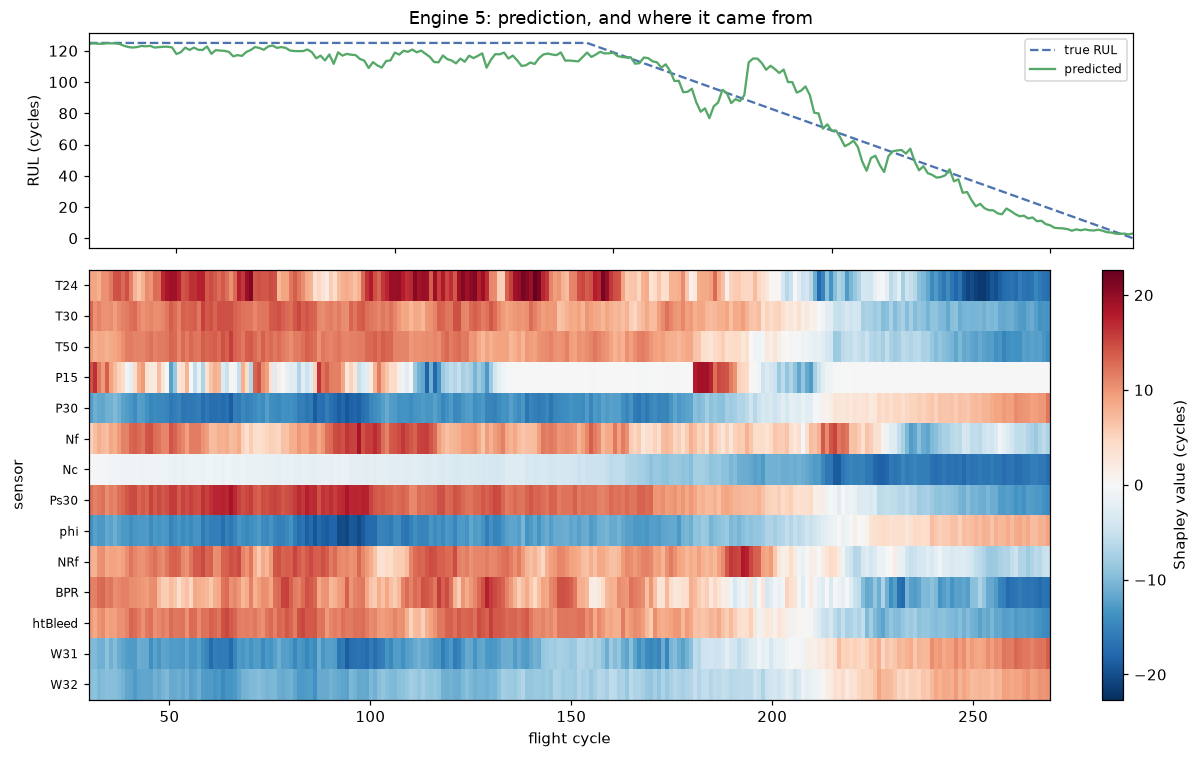

Red pushed the predicted life up, blue pushed it down. Notice the whole
picture inverting near the end of life, as the model switches from
'this engine is healthy' to 'this engine is nearly finished'.


In [18]:
sensors = list(prepared.sensor_symbols)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                         gridspec_kw={"height_ratios": [1, 2]})

axes[0].plot(attribution["end_cycle"], attribution["rul"], label="true RUL",
             color="#4C72B0", linestyle="--")
axes[0].plot(attribution["end_cycle"], attribution["predicted"], label="predicted",
             color="#55A868")
axes[0].set_ylabel("RUL (cycles)"); axes[0].legend(fontsize=8)
axes[0].set_title(f"Engine {engine}: prediction, and where it came from")

image = axes[1].imshow(
    attribution[sensors].to_numpy().T, aspect="auto", cmap="RdBu_r",
    vmin=-np.abs(attribution[sensors].to_numpy()).max(),
    vmax=+np.abs(attribution[sensors].to_numpy()).max(),
    extent=[attribution["end_cycle"].min(), attribution["end_cycle"].max(), 13.5, -0.5],
)
axes[1].set_yticks(range(14)); axes[1].set_yticklabels(sensors, fontsize=8)
axes[1].set_xlabel("flight cycle"); axes[1].set_ylabel("sensor")
fig.colorbar(image, ax=axes[1], fraction=0.03, label="Shapley value (cycles)")
fig.tight_layout(); plt.show()
print("Red pushed the predicted life up, blue pushed it down. Notice the whole")
print("picture inverting near the end of life, as the model switches from")
print("'this engine is healthy' to 'this engine is nearly finished'.")

### Which sensors mattered overall

The analogue of the ordering in the paper's Fig. 9. `mean_abs` is the average size of a sensor's contribution ignoring direction, which is the usual meaning of "importance"; `mean` keeps the sign, so a large negative value means the sensor consistently pulled the prediction down.

In [19]:
ranking = shap_summary(attribution[sensors].to_numpy(), sensors)
display(ranking)

,sensor,mean_abs,mean,max_abs
0,T24,11.905205,5.455171,22.650932
1,Ps30,11.327759,7.587595,18.750640
2,P30,11.226177,-8.386095,19.273761
3,phi,11.015320,-8.712854,20.662435
4,W31,10.166421,-6.141188,18.606229
5,htBleed,9.922131,5.201809,15.515825
6,T30,9.839698,5.547918,15.485988
7,T50,9.432500,4.950807,15.680219
8,BPR,9.034905,3.600807,17.610376
9,NRf,8.722260,6.830129,18.121229


**The built-in sanity check.** `P15` takes only two distinct values across the whole FD001 training set — 21.60 and 21.61 psia, which is the resolution of the recording rather than anything physical. A sensor carrying no information should rank last, and it does, on every engine tested. The paper's own Fig. 9 also places it last, which is a real point of agreement between this re-implementation and the original.

It is *not* near zero, though, and the reason is instructive: `P15` flips between its two levels at irregular moments, and min-max scaling stretches that 0.01 psia step across the full range, so a flip inside a window looks to the model like a full-scale event. Finding F-05 records this, and it is a neat demonstration for a thesis on explainability — **the explanation exposed a preprocessing defect, not a model defect.**

In [20]:
rank = int(ranking.index[ranking.sensor == "P15"][0]) + 1
print(f"P15 ranks {rank} of 14 by mean |contribution|.")
print(f"  P15  {float(ranking.loc[ranking.sensor=='P15','mean_abs'].iloc[0]):6.2f} cycles")
print(f"  top  {float(ranking['mean_abs'].iloc[0]):6.2f} cycles  ({ranking['sensor'].iloc[0]})")
assert rank == 14
print("\nOK  The least informative sensor is ranked last, as it should be.")

P15 ranks 14 of 14 by mean |contribution|.
  P15    4.17 cycles
  top   11.91 cycles  (T24)

OK  The least informative sensor is ranked last, as it should be.


## 8. Summary

What this notebook established, in order:

| # | Step | Result |
|---|------|--------|
| 9 | Built the network | 62 657 parameters; the Table 4 configuration has exactly 61 729, and the difference is the first weight matrix widening because the LSTM is omitted |
| 9 | Checked the graph | sensors four edges apart cannot influence each other under three layers, and `T24` is the only articulation point |
| 10 | Trained it | Table 6's settings, stopping on a held-out set the paper does not have |
| 11 | Scored it | four measures on 100 test engines, comparable only with the paper's `w/o LSTM` row |
| 11 | Ablated the graph | removing the physics prior costs far more here than the paper reports, most likely because the omitted LSTM would otherwise supply the same information (F-04) |
| 12 | Explained it | exact Shapley values, efficiency holding to floating-point precision, and `P15` correctly ranked last (F-05) |

### What this notebook is not

It is a single seed. The numbers reported for this project are means over five seeds, from `scripts/train.py --seeds 5`, and section 8 of `README.md` gives them with their standard deviations.

It is also not a reproduction of the paper. The LSTM is absent by design, eleven preprocessing and training choices are not specified by the paper and are recorded in `docs/ASSUMPTIONS.md`, and two of the paper's printed formulas could not be used as written. What it is: a complete, documented implementation of everything the paper specifies, measured honestly against the row of its own ablation table that describes this configuration.